In [1]:
import pandas as pd
import numpy as np

# ============================================================
# 1. Caricamento
# ============================================================
df = pd.read_csv("entsoe_data_processed_v2.1.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True)

print(f"Shape iniziale: {df.shape}")
print(f"Zone: {df['country'].nunique()}")

# ============================================================
# 2. Flag qualità come feature 
# ============================================================
print(f"\nRighe qualita_ok=False: {(df['qualita_ok'] == False).sum()}")
print("Per paese (qualita_ok=False):")
print(df.loc[df['qualita_ok'] == False, "country"].value_counts().to_string())

df["qualita_ok"] = df["qualita_ok"].astype(int)   # True→1, False→0
df = df.sort_values(["datetime", "country"]).reset_index(drop=True)
print(f"\nShape dopo (nessuna riga rimossa): {df.shape}")
print(f"Zone: {df['country'].nunique()}")

# ============================================================
# 3. Feature temporali in ORA LOCALE (Europe/Berlin)
# ============================================================
locale = df["datetime"].dt.tz_convert("Europe/Berlin")
df["ora"]              = locale.dt.hour
df["giorno_settimana"] = locale.dt.day_of_week
df["weekend"]          = (df["giorno_settimana"] >= 5).astype(int)
df["mese"]             = locale.dt.month   # solo per i fold di validazione, NON è feature

# Encoding ciclico: 23h e 0h sono "vicine"
df["ora_sin"] = np.sin(2 * np.pi * df["ora"] / 24)
df["ora_cos"] = np.cos(2 * np.pi * df["ora"] / 24)

# ============================================================
# 4. Split temporale: train = 2024, test = gen-giu 2025
# ============================================================
split_ts = pd.Timestamp("2025-01-01", tz="Europe/Berlin")
df["is_train"] = locale < split_ts          # assegnazione diretta, no .to_numpy()

df_train = df[df["is_train"]]
df_test  = df[~df["is_train"]]

print(f"\nTrain (2024): {len(df_train)} ore | Test (gen-giu 2025): {len(df_test)} ore")
print(f"Prezzo medio train: {df_train['price'].mean():.2f} €/MWh | "
      f"test: {df_test['price'].mean():.2f} €/MWh")

# ============================================================
# 5. Definizione delle feature
# ============================================================
features_produzione = [
    'solar', 'wind_onshore', 'wind_offshore', 'nuclear',
    'fossil_gas', 'fossil_hard_coal', 'fossil_brown_coal_lignite',
    'hydro_total', 'biomass', 'waste'
]
variabili_temporali = [
    'ora', 'giorno_settimana', 'weekend',
    'ora_sin', 'ora_cos', 'qualita_ok'
]

# 'mese' resta nel df_model (serve per i fold) ma verrà escluso da X
colonne_modello = features_produzione + variabili_temporali + ['country', 'price', 'is_train', 'mese']
df_model = df[colonne_modello].dropna()
print("\nRighe eliminate da dropna:", len(df) - len(df_model))   # deve essere 0

# ============================================================
# 6. One-Hot Encoding per 'country'
# ============================================================
df_encoded = pd.get_dummies(df_model, columns=['country'], drop_first=True, dtype=int)

# ============================================================
# 7. Split in Training Set (2024) e Test Set (2025)
# ============================================================
train = df_encoded[df_encoded['is_train']]
test  = df_encoded[~df_encoded['is_train']]

# ============================================================
# 8. Separazione X / y  (escludo 'mese' e 'is_train' da X)
# ============================================================
X_train = train.drop(columns=['price', 'is_train', 'mese'])
y_train = train['price']

X_test = test.drop(columns=['price', 'is_train', 'mese'])
y_test = test['price']

# mese per i fold temporali (resta fuori da X)
mese_train = train['mese'].to_numpy()

# ============================================================
# 9. Controlli anti-leakage
# ============================================================
assert "price" not in X_train.columns
assert "mese"  not in X_train.columns
assert "is_train" not in X_train.columns
assert len(X_train) == len(df_train) and len(X_test) == len(df_test)

print(f"\nX_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test  shape: {X_test.shape},  y_test  shape: {y_test.shape}")
print(f"\nColonne finali ({len(X_train.columns)}):")
print(list(X_train.columns))

Shape iniziale: (288288, 14)
Zone: 22

Righe qualita_ok=False: 4992
Per paese (qualita_ok=False):
country
CH         4320
IT_NORD     672

Shape dopo (nessuna riga rimossa): (288288, 14)
Zone: 22

Train (2024): 193248 ore | Test (gen-giu 2025): 95040 ore
Prezzo medio train: 79.57 €/MWh | test: 88.02 €/MWh

Righe eliminate da dropna: 0

X_train shape: (193248, 37), y_train shape: (193248,)
X_test  shape: (95040, 37),  y_test  shape: (95040,)

Colonne finali (37):
['solar', 'wind_onshore', 'wind_offshore', 'nuclear', 'fossil_gas', 'fossil_hard_coal', 'fossil_brown_coal_lignite', 'hydro_total', 'biomass', 'waste', 'ora', 'giorno_settimana', 'weekend', 'ora_sin', 'ora_cos', 'qualita_ok', 'country_BE', 'country_CH', 'country_CZ', 'country_DE_LU', 'country_DK_1', 'country_EE', 'country_ES', 'country_FR', 'country_HR', 'country_HU', 'country_IT_NORD', 'country_LT', 'country_LV', 'country_NL', 'country_NO_3', 'country_PL', 'country_PT', 'country_RO', 'country_SE_4', 'country_SI', 'country_SK']

In [2]:
import time
from sklearn.ensemble import RandomForestRegressor

#--------------------------------------------------------------------
# Addestramento del modello RandomForestRegressor
#--------------------------------------------------------------------

print("Addestramento del RandomForestRegressor in corso... (potrebbe richiedere alcuni minuti)")
t0 = time.time()

rf = RandomForestRegressor(
    n_estimators=100,        # numero di alberi
    min_samples_leaf=5,      # profondità
    n_jobs=-1,               # usa tutti i core
    random_state=42,
)
rf.fit(X_train, y_train)
print(f"Addestramento completato in {time.time() - t0:.0f} secondi")

Addestramento del RandomForestRegressor in corso... (potrebbe richiedere alcuni minuti)
Addestramento completato in 31 secondi


In [3]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Previsioni sul test set 2025
y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
bias = np.mean(y_pred - y_test)
rho = spearmanr(y_test, y_pred)[0]

print("\n--- Valutazione sul Test Set 2025 ---")
print(f"MAE  (Errore Assoluto Medio): {mae:.2f} €/MWh")
print(f"RMSE (Radice Errore Quadratico Medio): {rmse:.2f} €/MWh")
print(f"R²   (Coefficiente di Determinazione): {r2:.3f}")
print(f"Bias (previsto - reale, medio): {bias:+.2f} €/MWh")
print(f"Spearman (ordinamento dei prezzi): {rho:.3f}")

# Confronto con la baseline più forte che NON usa le fonti: media per zona, ora e tipo di giorno
medie = df_train.groupby(["country", "ora", "weekend"])["price"].mean().rename("pred")
y_base = df_test.join(medie, on=["country", "ora", "weekend"])["pred"].fillna(y_train.mean()).to_numpy()
mae_base = mean_absolute_error(y_test, y_base)
r2_base = r2_score(y_test, y_base)
print(f"\nBaseline (media per zona, ora, tipo di giorno): MAE {mae_base:.2f} | R² {r2_base:.3f}")
print(f"Riduzione dell'errore medio rispetto alla baseline: {(1 - mae / mae_base) * 100:.0f}%")

# Prime righe: previsioni contro realtà
confronto = pd.DataFrame({
    "Zona": df.loc[X_test.index, "country"].values,
    "Prezzo_Reale": y_test.values,
    "Prezzo_Previsto": y_pred,
}, index=X_test.index)
confronto["Errore_Assoluto"] = (confronto["Prezzo_Reale"] - confronto["Prezzo_Previsto"]).abs()

print("\nPrime righe delle previsioni vs realtà:")
print(confronto.head().to_string())

print("\nI 5 errori più grandi (di solito sono picchi di prezzo):")
print(confronto.sort_values("Errore_Assoluto", ascending=False).head(5).to_string())


--- Valutazione sul Test Set 2025 ---
MAE  (Errore Assoluto Medio): 29.99 €/MWh
RMSE (Radice Errore Quadratico Medio): 41.55 €/MWh
R²   (Coefficiente di Determinazione): 0.537
Bias (previsto - reale, medio): -7.16 €/MWh
Spearman (ordinamento dei prezzi): 0.775

Baseline (media per zona, ora, tipo di giorno): MAE 39.00 | R² 0.319
Riduzione dell'errore medio rispetto alla baseline: 23%

Prime righe delle previsioni vs realtà:
         Zona  Prezzo_Reale  Prezzo_Previsto  Errore_Assoluto
193248     AT        109.00       104.061390         4.938610
193249     BE         10.62        22.486066        11.866066
193250     CH        102.20        61.382544        40.817456
193251     CZ         21.00        88.805524        67.805524
193252  DE_LU          2.16        13.354439        11.194439

I 5 errori più grandi (di solito sono picchi di prezzo):
       Zona  Prezzo_Reale  Prezzo_Previsto  Errore_Assoluto
240378   EE        773.00       110.460018       662.539982
240385   LV        77

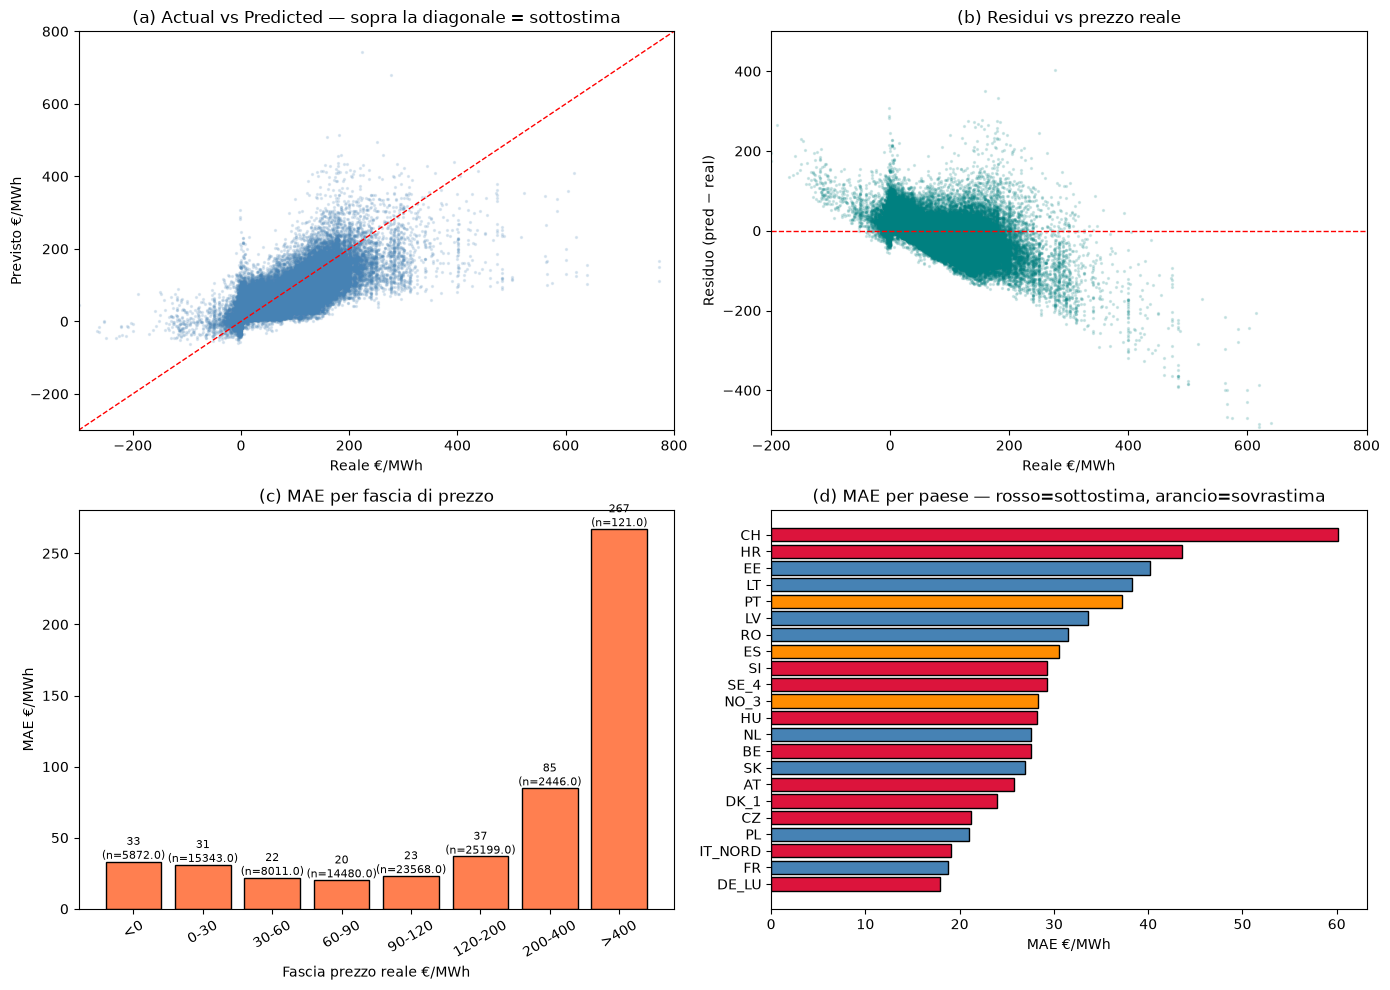

In [ ]:
import matplotlib.pyplot as plt

# DataFrame di lavoro
ev = pd.DataFrame({
    "price":   y_test.to_numpy(),
    "pred":    y_pred,
    "country": df_test["country"].to_numpy(),
})
ev["err"]    = ev["pred"] - ev["price"]
ev["abserr"] = ev["err"].abs()

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) Actual vs Predicted
ax[0,0].scatter(ev["price"], ev["pred"], s=2, alpha=0.15, color="steelblue")
ax[0,0].plot([-500,800],[-500,800], "r--", lw=1)
ax[0,0].set_xlim(-300,800); ax[0,0].set_ylim(-300,800)
ax[0,0].set_xlabel("Reale €/MWh"); ax[0,0].set_ylabel("Previsto €/MWh")
ax[0,0].set_title("(a) Actual vs Predicted — sopra la diagonale = sottostima")

# (b) Residui vs prezzo reale (mostra eteroschedasticità + bias per fascia)
ax[0,1].scatter(ev["price"], ev["err"], s=2, alpha=0.15, color="teal")
ax[0,1].axhline(0, color="red", ls="--", lw=1)
ax[0,1].set_xlim(-200,800); ax[0,1].set_ylim(-500,500)
ax[0,1].set_xlabel("Reale €/MWh"); ax[0,1].set_ylabel("Residuo (pred − real)")
ax[0,1].set_title("(b) Residui vs prezzo reale")

# (c) MAE per fascia di prezzo — il pannello chiave
bins   = [-500, 0, 30, 60, 90, 120, 200, 400, 2000]
labels = ["<0","0-30","30-60","60-90","90-120","120-200","200-400",">400"]
ev["fascia"] = pd.cut(ev["price"], bins=bins, labels=labels)
f = ev.groupby("fascia", observed=True).agg(mae=("abserr","mean"), n=("price","size"))
bars = ax[1,0].bar(f.index, f["mae"], color="coral", edgecolor="k")
for b, (m, n) in zip(bars, f[["mae","n"]].values):
    ax[1,0].text(b.get_x()+b.get_width()/2, b.get_height()+2,
                 f"{m:.0f}\n(n={n})", ha="center", fontsize=8)
ax[1,0].set_xlabel("Fascia prezzo reale €/MWh"); ax[1,0].set_ylabel("MAE €/MWh")
ax[1,0].set_title("(c) MAE per fascia di prezzo")
ax[1,0].tick_params(axis="x", rotation=30)

# (d) MAE per paese — colorato per bias
p = ev.groupby("country").agg(mae=("abserr","mean"), bias=("err","mean")).sort_values("mae")
colors = ["crimson" if b<-5 else ("darkorange" if b>5 else "steelblue") for b in p["bias"]]
ax[1,1].barh(p.index, p["mae"], color=colors, edgecolor="k")
ax[1,1].set_xlabel("MAE €/MWh")
ax[1,1].set_title("(d) MAE per paese — rosso=sottostima, arancio=sovrastima")

plt.tight_layout()
plt.show()

In [ ]:
import time
from sklearn.tree import DecisionTreeRegressor

#--------------------------------------------------------------------
# Addestramento del modello DecisionTreeRegressor
#--------------------------------------------------------------------

print("Addestramento DecisionTreeRegressor in corso...")
t0 = time.time()

dt = DecisionTreeRegressor(
    max_depth=None,         
    min_samples_leaf=5,     
    random_state=42,
)
dt.fit(X_train, y_train)

print(f"Addestramento completato in {time.time() - t0:.0f} secondi")

Addestramento DecisionTreeRegressor in corso...
Addestramento completato in 2 secondi


In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import spearmanr

def report(y_true, y_pred, name):
    print(f"{name:<28s} "
          f"MAE={mean_absolute_error(y_true, y_pred):6.2f} | "
          f"RMSE={np.sqrt(mean_squared_error(y_true, y_pred)):6.2f} | "
          f"R²={r2_score(y_true, y_pred):6.3f} | "
          f"bias={np.mean(y_pred - y_true):+6.2f} | "
          f"Spearman={spearmanr(y_true, y_pred)[0]:.3f}")

y_pred_dt = dt.predict(X_test)

print("--- TRAIN (per vedere l'overfitting) ---")
report(y_train, dt.predict(X_train), "DecisionTree (train)")

print("\n--- TEST ---")
report(y_test, y_pred_dt, "DecisionTree (test)")

print("\n--- CONFRONTO SUL TEST ---")
report(y_test, y_pred,     "RandomForest (rif.)")
report(y_test, y_pred_dt,  "DecisionTree")

np.save("pred_dt.npy", y_pred_dt)

--- TRAIN (per vedere l'overfitting) ---
DecisionTree (train)         MAE= 10.42 | RMSE= 21.15 | R²= 0.875 | bias= -0.00 | Spearman=0.957

--- TEST ---
DecisionTree (test)          MAE= 36.55 | RMSE= 53.81 | R²= 0.224 | bias= -7.49 | Spearman=0.674

--- CONFRONTO SUL TEST ---
RandomForest (rif.)          MAE= 29.99 | RMSE= 41.55 | R²= 0.537 | bias= -7.16 | Spearman=0.775
DecisionTree                 MAE= 36.55 | RMSE= 53.81 | R²= 0.224 | bias= -7.49 | Spearman=0.674


In [8]:
import time
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#--------------------------------------------------------------------
# Addestramento del modello KNeighborsRegressor
#--------------------------------------------------------------------

print("Addestramento KNeighborsRegressor in corso... (può richiedere qualche minuto)")
t0 = time.time()

knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(
        n_neighbors=30,
        weights="distance",   # vicini più vicini pesano di più
        n_jobs=-1,
    )),
])
knn.fit(X_train, y_train)

print(f"Addestramento completato in {time.time() - t0:.0f} secondi")

Addestramento KNeighborsRegressor in corso... (può richiedere qualche minuto)
Addestramento completato in 0 secondi


In [9]:
print("Predizione su test in corso...")
t0 = time.time()
y_pred_knn = knn.predict(X_test)
print(f"Predizione completata in {time.time() - t0:.0f} secondi\n")

print("--- TRAIN (per vedere overfitting) ---")
report(y_train, knn.predict(X_train), "KNN (train)")

print("\n--- TEST ---")
report(y_test, y_pred_knn, "KNN (test)")

print("\n--- CONFRONTO SUL TEST ---")
report(y_test, y_pred,      "RandomForest (rif.)")
report(y_test, y_pred_dt,   "DecisionTree")
report(y_test, y_pred_knn,  "KNN (k=30, distance)")

np.save("pred_knn.npy", y_pred_knn)

Predizione su test in corso... (potrebbe essere la parte lenta)
Predizione completata in 20 secondi

--- TRAIN (per vedere overfitting) ---
KNN (train)                  MAE=  0.00 | RMSE=  0.01 | R²= 1.000 | bias= -0.00 | Spearman=1.000

--- TEST ---
KNN (test)                   MAE= 30.97 | RMSE= 41.82 | R²= 0.531 | bias= -8.37 | Spearman=0.777

--- CONFRONTO SUL TEST ---
RandomForest (rif.)          MAE= 29.99 | RMSE= 41.55 | R²= 0.537 | bias= -7.16 | Spearman=0.775
DecisionTree                 MAE= 36.55 | RMSE= 53.81 | R²= 0.224 | bias= -7.49 | Spearman=0.674
KNN (k=30, distance)         MAE= 30.97 | RMSE= 41.82 | R²= 0.531 | bias= -8.37 | Spearman=0.777


In [10]:
import time

for k in [5, 10, 30, 50, 100]:
    pipe = Pipeline([
        ("sc",  StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k, weights="distance", n_jobs=-1)),
    ])
    pipe.fit(X_train, y_train)
    t0 = time.time()
    y_hat = pipe.predict(X_test)
    dt_pred = time.time() - t0
    report(y_test, y_hat, f"KNN k={k}  (predict {dt_pred:.0f}s)")

KNN k=5  (predict 18s)       MAE= 32.11 | RMSE= 44.42 | R²= 0.471 | bias= -8.56 | Spearman=0.753
KNN k=10  (predict 18s)      MAE= 31.25 | RMSE= 42.61 | R²= 0.513 | bias= -8.49 | Spearman=0.771
KNN k=30  (predict 19s)      MAE= 30.97 | RMSE= 41.82 | R²= 0.531 | bias= -8.37 | Spearman=0.777
KNN k=50  (predict 19s)      MAE= 31.38 | RMSE= 42.27 | R²= 0.521 | bias= -8.27 | Spearman=0.767
KNN k=100  (predict 19s)     MAE= 31.65 | RMSE= 42.47 | R²= 0.517 | bias= -8.45 | Spearman=0.767


In [11]:
import time
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def make_ridge(degree, alpha):
    """Ridge con espansione polinomiale sulle feature numeriche
    e passthrough sulle dummies country."""
    num_cols = [c for c in X_train.columns if not c.startswith("country_")]
    cat_cols = [c for c in X_train.columns if c.startswith("country_")]
    preproc = ColumnTransformer([
        ("poly", Pipeline([
            ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
            ("sc",   StandardScaler()),
        ]), num_cols),
        ("cat", "passthrough", cat_cols),
    ])
    return Pipeline([("prep",  preproc),
                     ("ridge", Ridge(alpha=alpha, random_state=42))])

# alpha crescente con il grado (più feature → più regolarizzazione)
alphas = {1: 10.0, 2: 100.0, 3: 1000.0}
ridge_models = {}

for deg in [1, 2, 3]:
    print(f"Training Ridge grado {deg} (alpha={alphas[deg]})...")
    t0 = time.time()
    m = make_ridge(degree=deg, alpha=alphas[deg])
    m.fit(X_train, y_train)
    ridge_models[deg] = m
    print(f"  → fatto in {time.time()-t0:.1f} s")

Training Ridge grado 1 (alpha=10.0)...
  → fatto in 0.2 s
Training Ridge grado 2 (alpha=100.0)...
  → fatto in 0.8 s
Training Ridge grado 3 (alpha=1000.0)...
  → fatto in 7.6 s


In [12]:
preds_ridge = {deg: m.predict(X_test) for deg, m in ridge_models.items()}

print("--- TEST ---")
for deg, y_hat in preds_ridge.items():
    report(y_test, y_hat, f"Ridge grado {deg}")

print("\n--- CONFRONTO CON I NON-LINEARI ---")
report(y_test, y_pred,     "RandomForest (rif.)")
report(y_test, y_pred_knn, "KNN k=30 (rif.)")
report(y_test, y_pred_dt,  "DecisionTree")

for deg, y_hat in preds_ridge.items():
    np.save(f"pred_ridge_g{deg}.npy", y_hat)

--- TEST ---
Ridge grado 1                MAE= 38.03 | RMSE= 50.87 | R²= 0.306 | bias= -8.27 | Spearman=0.606
Ridge grado 2                MAE= 34.68 | RMSE= 46.31 | R²= 0.425 | bias= -8.15 | Spearman=0.706
Ridge grado 3                MAE= 32.71 | RMSE= 43.93 | R²= 0.483 | bias= -7.34 | Spearman=0.748

--- CONFRONTO CON I NON-LINEARI ---
RandomForest (rif.)          MAE= 29.99 | RMSE= 41.55 | R²= 0.537 | bias= -7.16 | Spearman=0.775
KNN k=30 (rif.)              MAE= 30.97 | RMSE= 41.82 | R²= 0.531 | bias= -8.37 | Spearman=0.777
DecisionTree                 MAE= 36.55 | RMSE= 53.81 | R²= 0.224 | bias= -7.49 | Spearman=0.674


In [ ]:
import matplotlib.pyplot as plt

modelli = {
    "Baseline (zona,ora,weekend)": (39.00, 0.319),
    "Ridge g1":                    (38.03, 0.306),
    "DecisionTree":                (36.55, 0.224),
    "Ridge g2":                    (34.68, 0.425),
    "Ridge g3":                    (32.71, 0.483),
    "KNN k=30":                    (30.97, 0.531),
    "RandomForest":                (29.99, 0.537),
}

names = list(modelli.keys())
maes  = [v[0] for v in modelli.values()]
r2s   = [v[1] for v in modelli.values()]
x     = range(len(names))

fig, ax = plt.subplots(figsize=(11, 6))

# Barre = MAE (asse sinistro)
bars = ax.bar(x, maes, color="steelblue", edgecolor="k", alpha=0.85,
              label="MAE (€/MWh) — asse sinistro")

# Linea = R² (asse destro)
ax2 = ax.twinx()
line, = ax2.plot(x, r2s, "o-", color="crimson", lw=2, ms=8,
                 label="R² — asse destro")

# Etichette valoriali sulle barre
for xi, mae in zip(x, maes):
    ax.text(xi, mae + 0.4, f"{mae:.1f}", ha="center", va="bottom", fontsize=9)

# Etichette valoriali sulla linea R²
for xi, r2 in zip(x, r2s):
    ax2.text(xi, r2 + 0.015, f"{r2:.3f}", ha="center", va="bottom",
             fontsize=8, color="crimson")

# Assi
ax.set_xticks(list(x))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("MAE (€/MWh)", color="steelblue", fontsize=11)
ax2.set_ylabel("R²", color="crimson", fontsize=11)
ax.set_ylim(0, 45)
ax2.set_ylim(0, 0.65)
ax.set_title("Confronto modelli — test 2025", fontsize=13)

# Legenda UNICA con i due elementi
handles = [bars, line]
labels  = [h.get_label() for h in handles]
ax.legend(handles, labels, loc="upper right", frameon=True, fontsize=10)

# Evidenzia il vincitore (RandomForest) con una cornice
ax.patches[-1].set_edgecolor("gold")
ax.patches[-1].set_linewidth(2.5)

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Grafici delle previsioni sul test per ogni modello addestrato
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, r2_score

predizioni_test = {
    "Random Forest": y_pred,
    "Decision Tree": y_pred_dt,
    "KNN (k=30)": y_pred_knn,
    **{f"Ridge (grado {grado})": pred for grado, pred in preds_ridge.items()},
}

# Il campionamento serve solo a rendere leggibile il grafico; le metriche
# vengono calcolate su tutte le osservazioni del test.
max_punti = 15000
rng = np.random.default_rng(42)
if len(y_test) > max_punti:
    indici_grafico = np.sort(rng.choice(len(y_test), size=max_punti, replace=False))
else:
    indici_grafico = np.arange(len(y_test))

n_modelli = len(predizioni_test)
n_colonne = 2
n_righe = (n_modelli + n_colonne - 1) // n_colonne
fig, assi = plt.subplots(n_righe, n_colonne, figsize=(14, 5 * n_righe), squeeze=False)
limite_min = min(float(y_test.min()), min(float(pred.min()) for pred in predizioni_test.values()))
limite_max = max(float(y_test.max()), max(float(pred.max()) for pred in predizioni_test.values()))

for ax, (nome, pred) in zip(assi.flat, predizioni_test.items()):
    ax.scatter(y_test.iloc[indici_grafico], pred[indici_grafico], s=5, alpha=0.2)
    ax.plot([limite_min, limite_max], [limite_min, limite_max], "r--", lw=1)
    ax.set_xlim(limite_min, limite_max)
    ax.set_ylim(limite_min, limite_max)
    ax.set_xlabel("Prezzo reale (€/MWh)")
    ax.set_ylabel("Prezzo previsto (€/MWh)")
    ax.set_title(
        f"{nome} — test\nMAE: {mean_absolute_error(y_test, pred):.2f} €/MWh | "
        f"R²: {r2_score(y_test, pred):.3f}"
    )
    ax.grid(alpha=0.2)

for ax in assi.flat[n_modelli:]:
    ax.set_visible(False)

fig.suptitle("Prezzi reali vs previsti sul test (punti sopra la diagonale = sovrastima)", y=1.01)
fig.tight_layout()
plt.show()
